In [ ]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

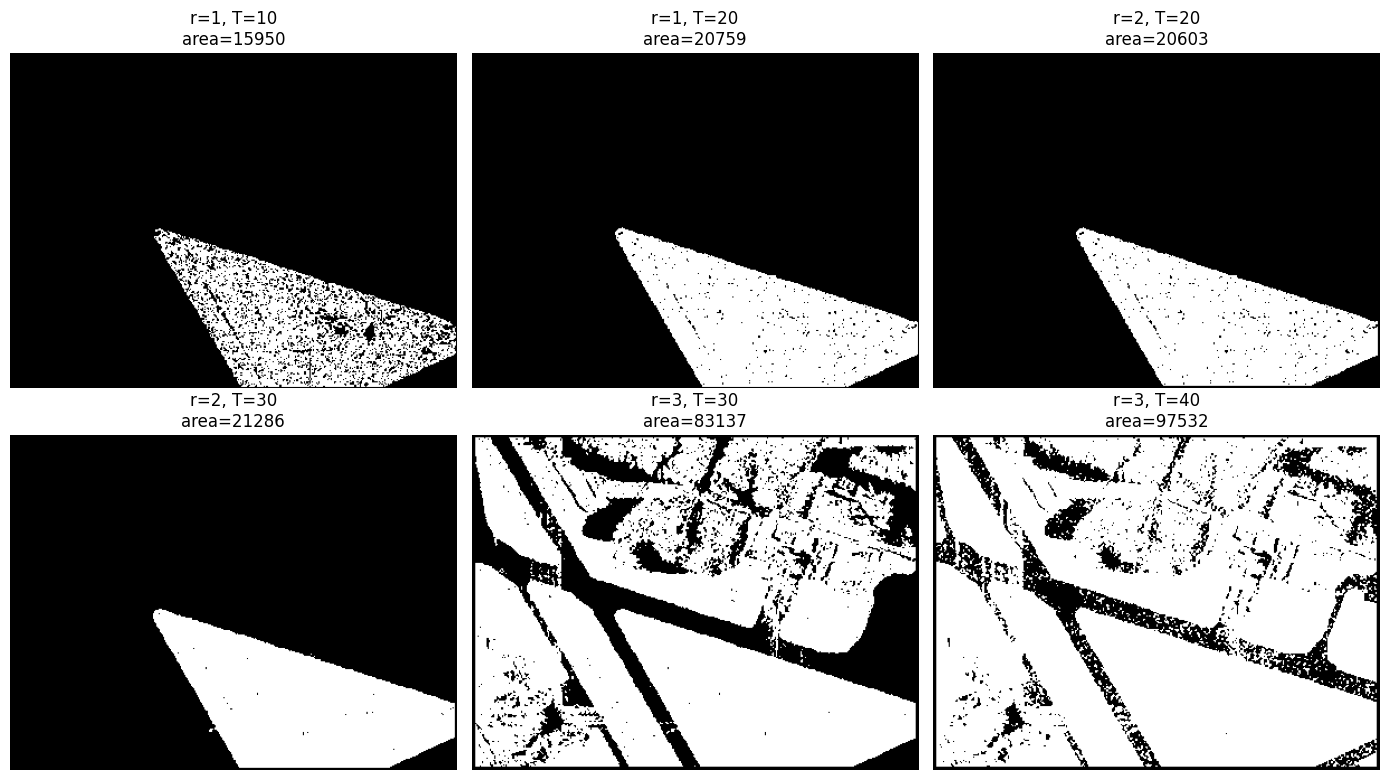

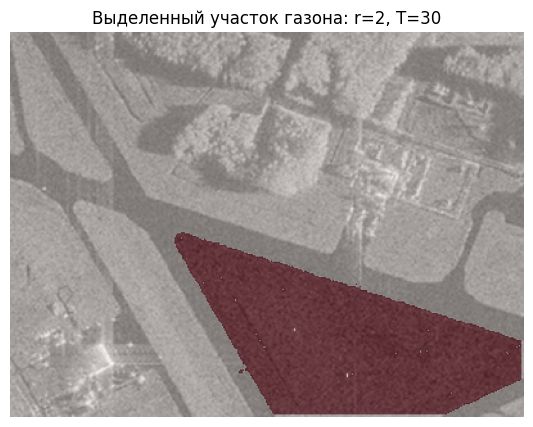

In [61]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


#Задание 1
def homo_average(img, mask, point, T):
    vals = img[mask > 0].astype(np.float32)
    if vals.size == 0:
        return False
    av_val = vals.mean()
    return abs(float(img[point]) - av_val) <= T

def region_growing(image, seed_point, homo_fun, r, T, verbose=False):

    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1

    kernel = np.ones((2 * r + 1, 2 * r + 1), np.uint8)
    h, w = image.shape

    while count > 0:

        av_val = float(image[mask > 0].astype(np.float32).mean())
        dilated = cv2.dilate(mask, kernel)
        candidates = (dilated > 0) & (mask == 0)

        candidates[:r, :] = False
        candidates[h - r:, :] = False
        candidates[:, :r] = False
        candidates[:, w - r:] = False

        ii, jj = np.where(candidates)
        if ii.size == 0:
            break


        diff = np.abs(image[ii, jj].astype(np.float32) - av_val)
        good = diff <= T

        count = int(good.sum())
        if verbose:
            print(count)
        if count == 0:
            break

        mask[ii[good], jj[good]] = 1

    return (mask * 255).astype(np.uint8)

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

seed_point = (250, 250)

params = [(1, 10), (1, 20), (2, 20), (2, 30), (3, 30), (3, 40)]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (r, T) in zip(axes.ravel(), params):
    m = region_growing(image_gray, seed_point, homo_average, r=r, T=T)
    ax.imshow(m, cmap='gray')
    ax.set_title(f'r={r}, T={T}\narea={np.count_nonzero(m)}')
    ax.axis('off')

plt.tight_layout()
plt.show()

mask_lawn = region_growing(image_gray, seed_point, homo_average, r=2, T=30)

plt.figure(figsize=(7, 5))
plt.imshow(image_gray, cmap='gray')
plt.imshow(mask_lawn, cmap='Reds', alpha=0.45)
plt.title('Выделенный участок газона: r=2, T=30')
plt.axis('off')
plt.show()

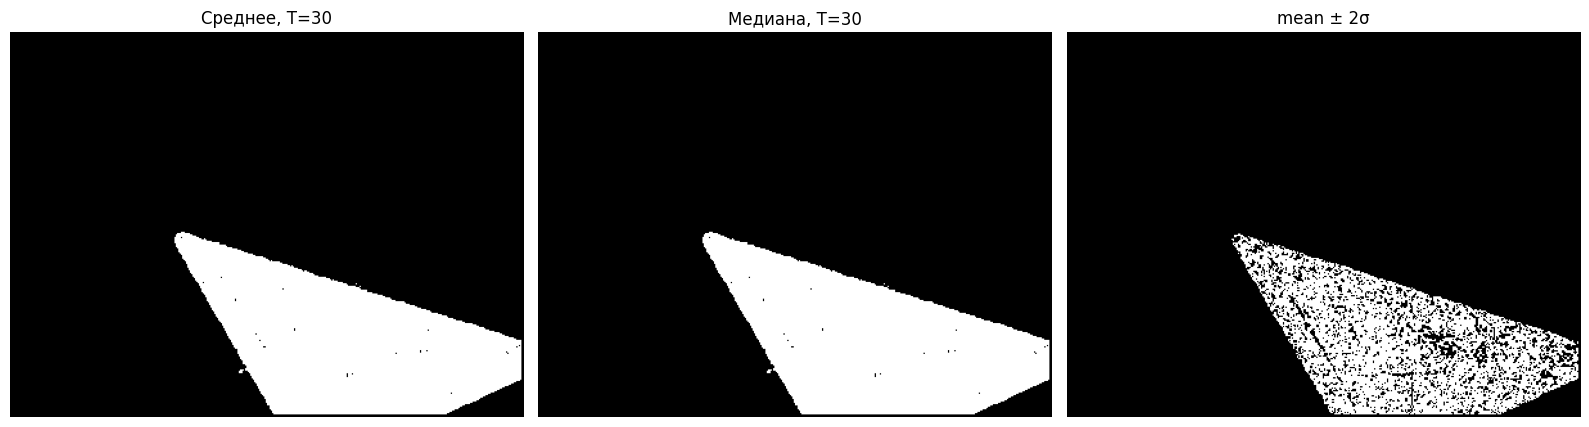

Площадь, среднее: 21286
Площадь, медиана: 21286
Площадь, mean±2σ: 15875


In [66]:
#Задание 2

def homo_median(img, mask, point, T):
    vals = img[mask > 0].astype(np.float32)
    med = np.median(vals)
    return abs(float(img[point]) - med) <= T

def homo_std(img, mask, point, T):
    vals = img[mask > 0].astype(np.float32)
    mu = vals.mean()
    sigma = vals.std()
    return abs(float(img[point]) - mu) <= T * max(sigma, 1.0)

mask_avg = region_growing(image_gray, seed_point, homo_average, r=2, T=30)
mask_med = region_growing(image_gray, seed_point, homo_median, r=2, T=30)
mask_std = region_growing(image_gray, seed_point, homo_std, r=2, T=10.0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(mask_avg, cmap='gray')
axes[0].set_title('Среднее, T=30')

axes[1].imshow(mask_med, cmap='gray')
axes[1].set_title('Медиана, T=30')

axes[2].imshow(mask_std, cmap='gray')
axes[2].set_title('mean ± 2σ')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

print('Площадь, среднее:', np.count_nonzero(mask_avg))
print('Площадь, медиана:', np.count_nonzero(mask_med))
print('Площадь, mean±2σ:', np.count_nonzero(mask_std))

Найдено пальм: 82


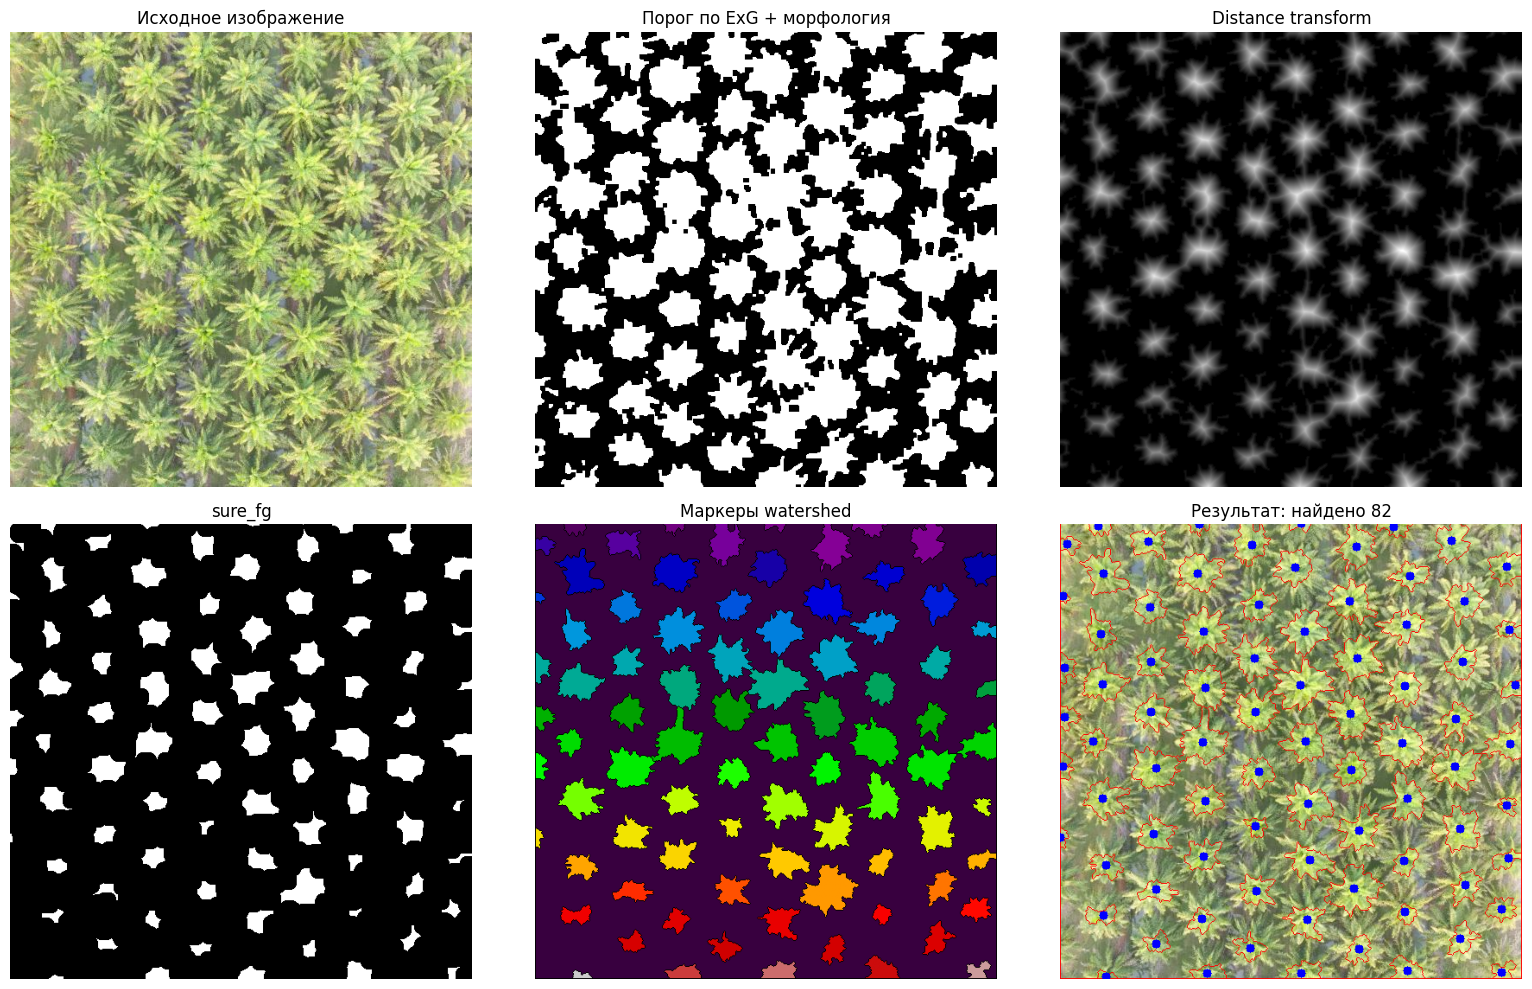

In [57]:
image = cv2.imread('palm_1.jpg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


b, g, r = cv2.split(image.astype(np.int16))
exg = 2 * g - r - b
exg = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

ret, thresh = cv2.threshold(
    exg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)


kernel = np.ones((3, 3), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=1)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)


ret, sure_fg = cv2.threshold(
    dist, 0.35 * dist.max(), 255, cv2.THRESH_BINARY
)
sure_fg = sure_fg.astype(np.uint8)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(sure_fg)

min_area = 20
clean_fg = np.zeros_like(sure_fg)
centers = []
count = 0

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]
    if area >= min_area:
        clean_fg[labels == i] = 255
        centers.append(tuple(np.int32(centroids[i])))
        count += 1

num, markers = cv2.connectedComponents(clean_fg)
markers = markers + 1
unknown = cv2.subtract(thresh, clean_fg)
markers[unknown == 255] = 0

markers = cv2.watershed(image, markers)

out = image_rgb.copy()
out[markers == -1] = [255, 0, 0]

for c in centers:
    cv2.circle(out, c, 5, (0, 0, 255), -1)

print('Найдено пальм:', count)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title('Исходное изображение')

axes[0, 1].imshow(thresh, cmap='gray')
axes[0, 1].set_title('Порог по ExG + морфология')

axes[0, 2].imshow(dist, cmap='gray')
axes[0, 2].set_title('Distance transform')

axes[1, 0].imshow(sure_fg, cmap='gray')
axes[1, 0].set_title('sure_fg')

axes[1, 1].imshow(markers, cmap='nipy_spectral')
axes[1, 1].set_title('Маркеры watershed')

axes[1, 2].imshow(out)
axes[1, 2].set_title(f'Результат: найдено {count}')

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()

Критерии по среднему и медиане дают практически одинаковую область — на SAR-снимке газон достаточно однороден, поэтому медиана не даёт заметного выигрыша. Критерий mean ± 10σ при подобранном T=10 выделяет почти ту же площадь, но с небольшими пробелами внутри — из-за того, что σ пересчитывается по мере роста маски и адаптивный коридор сужается.